In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('Tweets.csv')
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [3]:
df = df[['text', 'airline_sentiment']].copy()

In [4]:
df.head()

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


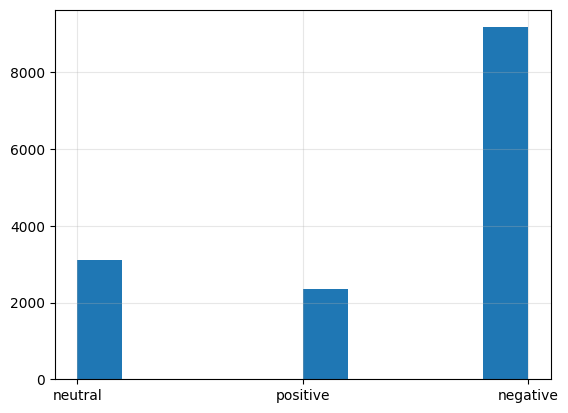

In [5]:
df['airline_sentiment'].hist()
plt.grid(alpha=0.3)
plt.show()

In [6]:
target_map = {'negative': 0, 'positive': 1, 'neutral': 2}

df['target'] = df['airline_sentiment'].map(target_map)

In [7]:
df.sample(5)

,text,airline_sentiment,target
12789,@AmericanAir dont send me a tweet to cover you...,negative,0
10337,@USAirways #Wronganswer. Talk is cheap. Custom...,negative,0
6350,@SouthwestAir Not possible to carry-on and put...,neutral,2
5199,@SouthwestAir Worst customer service ever. You...,negative,0
8154,@JetBlue the slowest boarding process I've eve...,negative,0


## Datset Split

In [8]:
X_train , X_test, y_train, y_test = train_test_split(df['text'], df['target'], test_size=0.2, random_state=42)

X_train.shape, X_test.shape

((11712,), (2928,))

In [9]:
vectorizer = TfidfVectorizer(max_features=5000)

In [10]:
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

In [11]:
X_train.shape, X_test.shape

((11712, 5000), (2928, 5000))

## Model Training

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [13]:
print("Train Accuracy: ", model.score(X_train, y_train))
print("Test Accuracy: ", model.score(X_test, y_test))

Train Accuracy:  0.8702185792349727
Test Accuracy:  0.8049863387978142


In [14]:
y_pred = model.predict(X_test)

print("Classification Report : \n", classification_report(y_test, y_pred))

Classification Report : 
               precision    recall  f1-score   support

           0       0.84      0.93      0.88      1889
           1       0.80      0.63      0.70       459
           2       0.67      0.53      0.59       580

    accuracy                           0.80      2928
   macro avg       0.77      0.70      0.72      2928
weighted avg       0.80      0.80      0.80      2928



In [16]:
y_pred_prob = model.predict_proba(X_test)

print("ROC AUC Score : ", roc_auc_score(y_test, y_pred_prob, multi_class='ovo'))

ROC AUC Score :  0.8972410805701457


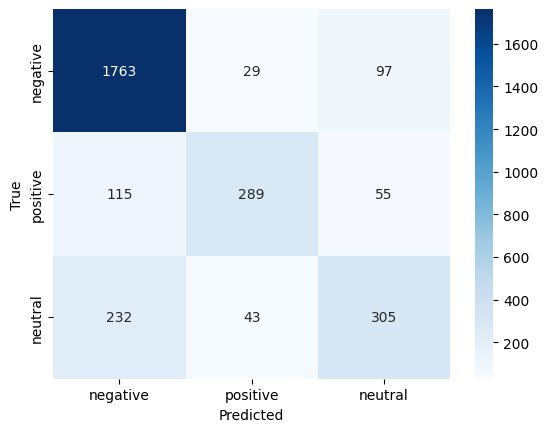

In [17]:
cm = confusion_matrix(y_test, y_pred)
classes = ['negative', 'positive', 'neutral']
df_cm = pd.DataFrame(cm, index=classes, columns=classes)
ax = sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
ax.set_label('Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.show()

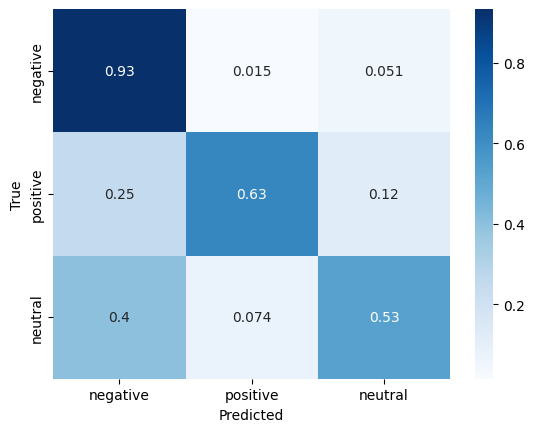

In [20]:
cm = confusion_matrix(y_test, y_pred, normalize='true')
classes = ['negative', 'positive', 'neutral']
df_cm = pd.DataFrame(cm, index=classes, columns=classes)
ax = sns.heatmap(df_cm, annot=True,  cmap='Blues')
ax.set_label('Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.show()